**Implémentation LeNet5 pour** **AMHCD**

*1-Installation et* *imports*

In [2]:
!pip -q install kagglehub

import os, copy, random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

Device : cuda


*2-Téléchargement de la base AMHCD*

In [3]:
import kagglehub
path = kagglehub.dataset_download("benaddym/amazigh-handwritten-character-database-amhcd")
print("Chemin :", path)

100%|██████████| 67.9M/67.9M [00:04<00:00, 16.4MB/s]

Extracting files...


Chemin : /root/.cache/kagglehub/datasets/benaddym/amazigh-handwritten-character-database-amhcd/versions/1


*3-Exploration de la base*

Racine : /root/.cache/kagglehub/datasets/benaddym/amazigh-handwritten-character-database-amhcd/versions/1/AMHCD_64/AMHCD_64
Nombre de classes : 33
Total images : 25740
Images/classe (min, max) : 780 780


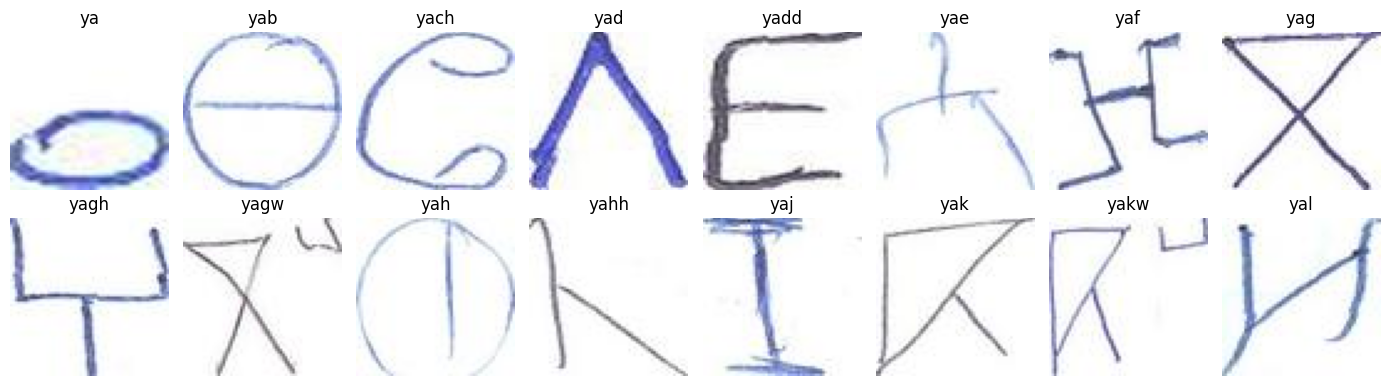

In [4]:
EXTS = ('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')
dirs = defaultdict(list)
for r, _, fs in os.walk(path):
    for f in fs:
        if f.lower().endswith(EXTS):
            dirs[r].append(os.path.join(r, f))


parents = defaultdict(list)
for d in dirs:
    parents[os.path.dirname(d)].append(d)
root = max(parents, key=lambda p: len(parents[p]))
class_dirs = sorted(parents[root])
class_names = [os.path.basename(d) for d in class_dirs]

print("Racine :", root)
print("Nombre de classes :", len(class_names))
print("Total images :", sum(len(dirs[d]) for d in class_dirs))
print("Images/classe (min, max) :",
      min(len(dirs[d]) for d in class_dirs), max(len(dirs[d]) for d in class_dirs))


fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for a, d in zip(ax.ravel(), class_dirs[:16]):
    a.imshow(Image.open(dirs[d][0]).convert("RGB")); a.set_title(os.path.basename(d)); a.axis("off")
plt.tight_layout(); plt.savefig("apercu_dataset.png", dpi=200); plt.show()

*4-Prétraitement et découpage Train , Validation et Test*

In [5]:
IMG_SIZE = 32

X, y = [], []
for ci, d in enumerate(class_dirs):
    for f in dirs[d]:
        img = Image.open(f).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        X.append(np.asarray(img, dtype=np.uint8)); y.append(ci)
X = np.stack(X); y = np.array(y)
print("X :", X.shape, "| y :", y.shape)


X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te   = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print("Train/Val/Test :", len(X_tr), len(X_va), len(X_te))

def to_tensor(a):
    return torch.tensor(a, dtype=torch.float32).permute(0, 3, 1, 2) / 255.

Xtr, Xva, Xte = map(to_tensor, (X_tr, X_va, X_te))
mean = Xtr.mean((0, 2, 3), keepdim=True); std = Xtr.std((0, 2, 3), keepdim=True)
Xtr, Xva, Xte = [(t - mean) / std for t in (Xtr, Xva, Xte)]

BATCH = 64
train_loader = DataLoader(TensorDataset(Xtr, torch.tensor(y_tr)), batch_size=BATCH, shuffle=True)
val_loader   = DataLoader(TensorDataset(Xva, torch.tensor(y_va)), batch_size=256)
test_loader  = DataLoader(TensorDataset(Xte, torch.tensor(y_te)), batch_size=256)

X : (25740, 32, 32, 3) | y : (25740,)
Train/Val/Test : 18018 3861 3861


5-Architecture LeNet-5

In [6]:
def conv_layer(in_c, out_c, k=5, stride=1, padding=0):
    return nn.Conv2d(in_c, out_c, kernel_size=k, stride=stride, padding=padding)

def pool_layer(kind="avg", k=2, stride=2):
    return nn.AvgPool2d(k, stride) if kind == "avg" else nn.MaxPool2d(k, stride)

def fc_layer(n_in, n_out):
    return nn.Linear(n_in, n_out)

def activation(name="tanh"):
    return {"tanh": nn.Tanh(), "relu": nn.ReLU(), "sigmoid": nn.Sigmoid()}[name]

class LeNet5(nn.Module):
    def __init__(self, in_channels=3, num_classes=33, act="tanh", pool="avg",
                 c1=6, c3=16, c5=120, f6=84, dropout=0.0):
        super().__init__()
        self.features = nn.Sequential(
            conv_layer(in_channels, c1, 5), activation(act), pool_layer(pool),   # C1, S2
            conv_layer(c1, c3, 5),          activation(act), pool_layer(pool),   # C3, S4
            conv_layer(c3, c5, 5),          activation(act),                     # C5 (conv 5x5 -> 1x1)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            fc_layer(c5, f6), activation(act), nn.Dropout(dropout),              # F6
            fc_layer(f6, num_classes),                                           # Sortie
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = LeNet5(num_classes=len(class_names)).to(device)
print(model)
print("Paramètres :", sum(p.numel() for p in model.parameters()))

LeNet5(
  (features): Sequential(
    (0): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
    (7): Tanh()
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=120, out_features=84, bias=True)
    (2): Tanh()
    (3): Dropout(p=0.0, inplace=False)
    (4): Linear(in_features=84, out_features=33, bias=True)
  )
)
Paramètres : 63961


*6-Fonctions d’apprentissage (train / validation / test)*

In [7]:
def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    tot_loss, correct, n = 0., 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb); loss = criterion(out, yb)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            tot_loss += loss.item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
    return tot_loss / n, correct / n

def fit(model, optimizer, epochs=30, verbose=True):
    criterion = nn.CrossEntropyLoss()
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc, best_state = 0, None
    for ep in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        for k, v in zip(hist, (tl, vl, ta, va)): hist[k].append(v)
        if va > best_acc: best_acc, best_state = va, copy.deepcopy(model.state_dict())
        if verbose and (ep % 5 == 0 or ep == 1):
            print(f"Ep {ep:02d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")
    model.load_state_dict(best_state)   # meilleur modèle sur validation
    return hist

def evaluate(model, loader):
    model.eval(); preds, trues = [], []
    with torch.no_grad():
        for xb, yb in loader:
            preds.append(model(xb.to(device)).argmax(1).cpu()); trues.append(yb)
    return torch.cat(trues).numpy(), torch.cat(preds).numpy()

*7-Algorithmes d’optimisation*

In [8]:
def get_optimizer(name, params, lr=1e-3):
    name = name.lower()
    if name == "sgd":      return torch.optim.SGD(params, lr=lr)
    if name == "momentum": return torch.optim.SGD(params, lr=lr, momentum=0.9)
    if name == "rmsprop":  return torch.optim.RMSprop(params, lr=lr)
    if name == "adam":     return torch.optim.Adam(params, lr=lr)
    raise ValueError(name)

*8-Entraînement du modèle principal (Adam)*

In [9]:
EPOCHS = 30
torch.manual_seed(SEED)
model = LeNet5(num_classes=len(class_names)).to(device)
opt = get_optimizer("adam", model.parameters(), lr=1e-3)
t0 = time.time()
history = fit(model, opt, epochs=EPOCHS)
print(f"Temps d'entraînement : {time.time()-t0:.1f}s")

Ep 01 | train loss 1.1177 acc 0.7650 | val loss 0.3973 acc 0.9091
Ep 05 | train loss 0.0597 acc 0.9880 | val loss 0.0778 acc 0.9803
Ep 10 | train loss 0.0119 acc 0.9981 | val loss 0.0531 acc 0.9852
Ep 15 | train loss 0.0081 acc 0.9982 | val loss 0.0768 acc 0.9793
Ep 20 | train loss 0.0042 acc 0.9991 | val loss 0.0590 acc 0.9842
Ep 25 | train loss 0.0007 acc 0.9999 | val loss 0.0532 acc 0.9873
Ep 30 | train loss 0.0003 acc 0.9999 | val loss 0.0524 acc 0.9881
Temps d'entraînement : 32.5s


*9-Courbes de loss et d’accuracy*

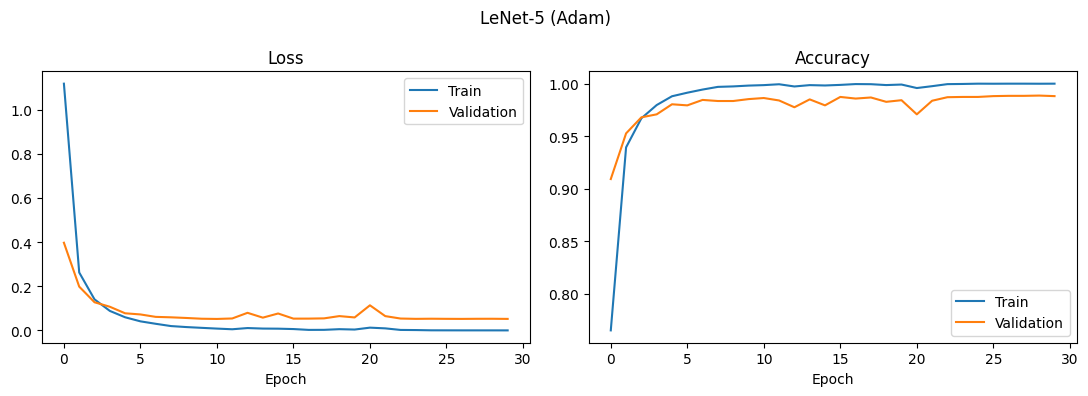

In [10]:
def plot_history(h, title="LeNet-5 (Adam)", fname="courbes.png"):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h["train_loss"], label="Train"); ax[0].plot(h["val_loss"], label="Validation")
    ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(h["train_acc"], label="Train"); ax[1].plot(h["val_acc"], label="Validation")
    ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    fig.suptitle(title); plt.tight_layout(); plt.savefig(fname, dpi=200); plt.show()

plot_history(history)

*10-Évaluation sur le test et matrice de confusion*

Accuracy test : 0.9829

              precision    recall  f1-score   support

          ya      1.000     1.000     1.000       117
         yab      1.000     1.000     1.000       117
        yach      0.991     0.991     0.991       117
         yad      1.000     0.991     0.996       117
        yadd      1.000     1.000     1.000       117
         yae      1.000     1.000     1.000       117
         yaf      1.000     0.966     0.983       117
         yag      0.991     0.983     0.987       117
        yagh      0.983     0.983     0.983       117
        yagw      0.975     0.983     0.979       117
         yah      0.983     0.991     0.987       117
        yahh      0.983     0.991     0.987       117
         yaj      0.991     0.983     0.987       117
         yak      0.966     0.974     0.970       117
        yakw      0.975     0.991     0.983       117
         yal      0.983     0.983     0.983       117
         yam      0.975     1.000     0.987       117
   

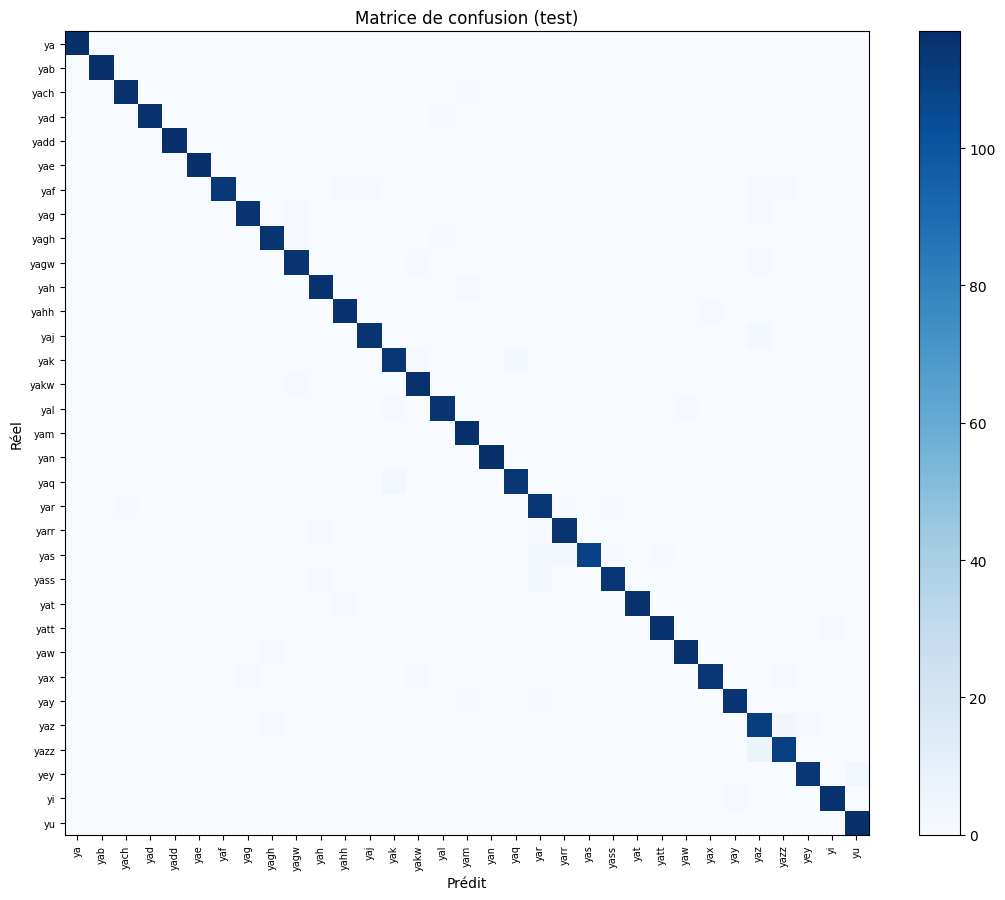

In [11]:
y_true, y_pred = evaluate(model, test_loader)
print(f"Accuracy test : {accuracy_score(y_true, y_pred):.4f}\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(11, 9))
plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(len(class_names)), class_names, rotation=90, fontsize=7)
plt.yticks(range(len(class_names)), class_names, fontsize=7)
plt.xlabel("Prédit"); plt.ylabel("Réel"); plt.title("Matrice de confusion (test)")
plt.tight_layout(); plt.savefig("confusion.png", dpi=200); plt.show()

*11-Visualisation des cartes de caractéristiques*

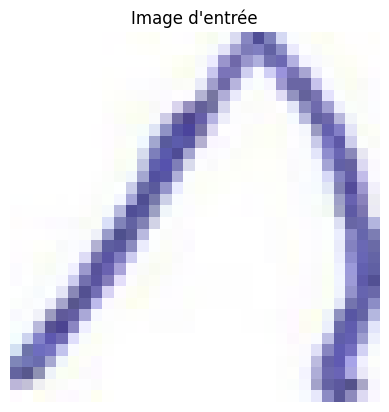

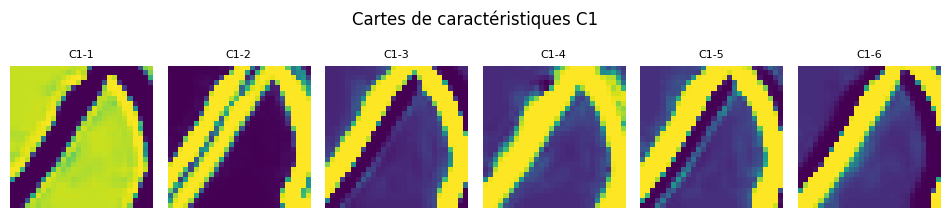

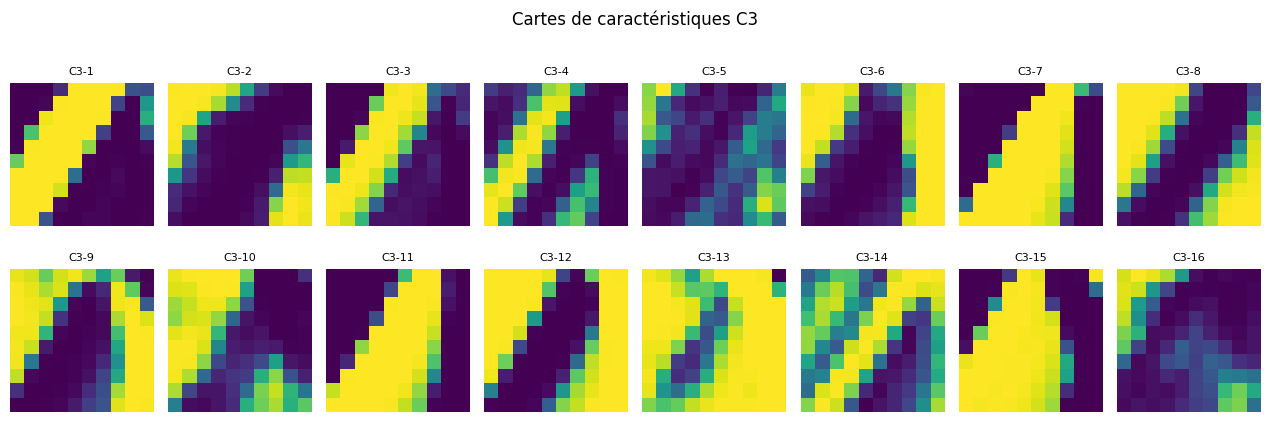

In [15]:
def show_feature_maps(model, img, stage="C1", fname=None):
    model.eval()
    with torch.no_grad():
        x = img.unsqueeze(0).to(device)
        fm = model.features[:2](x) if stage == "C1" else model.features[:5](x)
    fm = fm.squeeze(0).cpu(); n = fm.shape[0]
    cols = 6 if n == 6 else 8; rows = int(np.ceil(n / cols))
    fig, ax = plt.subplots(rows, cols, figsize=(cols * 1.6, rows * 2.3))
    for i, a in enumerate(np.array(ax).ravel()):
        a.axis("off")
        if i < n: a.imshow(fm[i], cmap="viridis"); a.set_title(f"{stage}-{i+1}", fontsize=8)
    plt.suptitle(f"Cartes de caractéristiques {stage}"); plt.tight_layout()
    if fname: plt.savefig(fname, dpi=200)
    plt.show()

sample = Xte[0]
plt.imshow((sample * std[0] + mean[0]).permute(1, 2, 0).clamp(0, 1)); plt.title("Image d'entrée"); plt.axis("off"); plt.show()
show_feature_maps(model, sample, "C1", "fmaps_c1.png")
show_feature_maps(model, sample, "C3", "fmaps_c3.png")

*12-Résultats qualitatifs (prédictions et erreurs)*

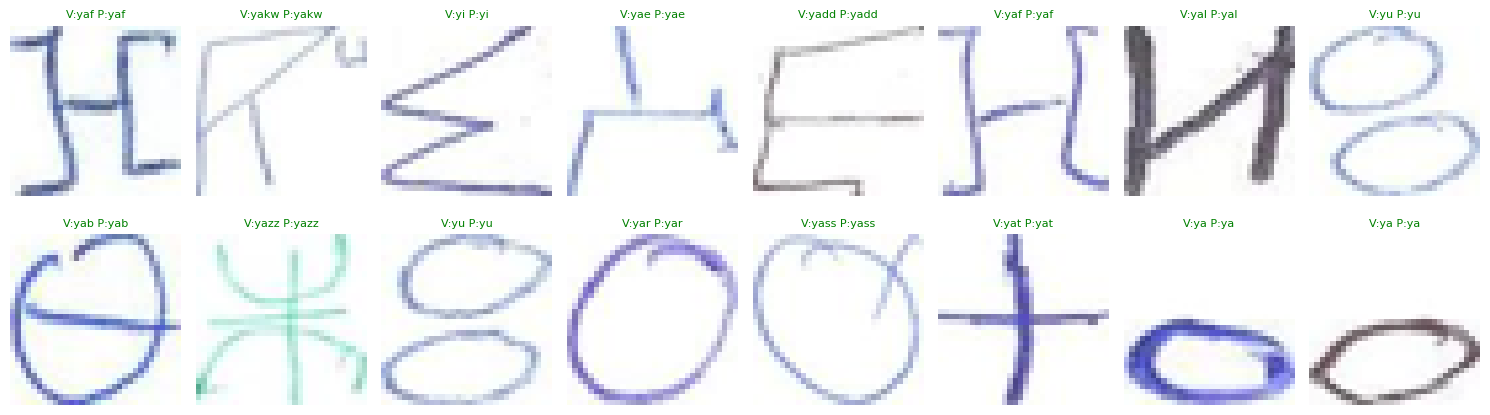

In [13]:
model.eval()
with torch.no_grad():
    pred = model(Xte.to(device)).argmax(1).cpu().numpy()
idx = np.random.choice(len(Xte), 16, replace=False)

fig, ax = plt.subplots(2, 8, figsize=(15, 4.5))
for a, i in zip(ax.ravel(), idx):
    a.imshow((Xte[i] * std[0] + mean[0]).permute(1, 2, 0).clamp(0, 1))
    ok = pred[i] == y_te[i]
    a.set_title(f"V:{class_names[y_te[i]]} P:{class_names[pred[i]]}", color="green" if ok else "red", fontsize=8)
    a.axis("off")
plt.tight_layout(); plt.savefig("predictions.png", dpi=200); plt.show()

*13-Comparaison des optimiseurs*

Optimiseur    LR  Val acc  Test acc
       sgd 0.010   0.8845    0.8969
  momentum 0.010   0.9793    0.9811
   rmsprop 0.001   0.9832    0.9780
      adam 0.001   0.9863    0.9793


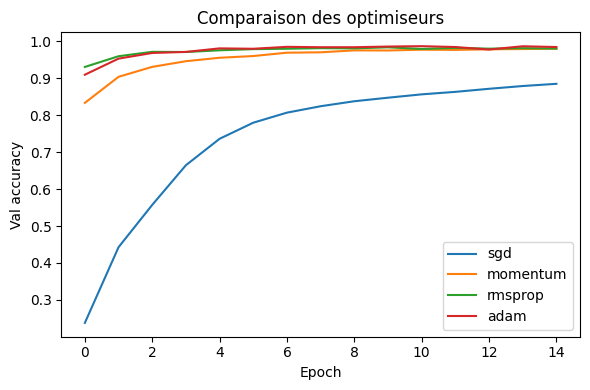

In [14]:
EPOCHS_CMP = 15
results, histories = [], {}
for name, lr in [("sgd", 1e-2), ("momentum", 1e-2), ("rmsprop", 1e-3), ("adam", 1e-3)]:
    torch.manual_seed(SEED)
    m = LeNet5(num_classes=len(class_names)).to(device)
    h = fit(m, get_optimizer(name, m.parameters(), lr), epochs=EPOCHS_CMP, verbose=False)
    yt, yp = evaluate(m, test_loader)
    histories[name] = h
    results.append({"Optimiseur": name, "LR": lr,
                    "Val acc": max(h["val_acc"]), "Test acc": accuracy_score(yt, yp)})
df = pd.DataFrame(results).round(4)
print(df.to_string(index=False)); df.to_csv("comparaison_optimiseurs.csv", index=False)

plt.figure(figsize=(6, 4))
for n, h in histories.items(): plt.plot(h["val_acc"], label=n)
plt.xlabel("Epoch"); plt.ylabel("Val accuracy"); plt.legend(); plt.title("Comparaison des optimiseurs")
plt.tight_layout(); plt.savefig("comparaison_optimiseurs.png", dpi=200); plt.show()